# Session 5 - Q2. Non-Linear Filtering

Apply the following non-linear filters to a noisy image:
1. Median filter
2. Minimum filter
3. Maximum filter

Test the filters using different kernel sizes and determine which filter is most suitable for removing salt-and-pepper noise.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image_path = "input.jpg"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

In [3]:
# Add salt-and-pepper noise
noisy_image = image.copy()
noise_probability = 0.05

salt = np.random.rand(*image.shape) < (noise_probability / 2)
pepper = np.random.rand(*image.shape) < (noise_probability / 2)

noisy_image[salt] = 255
noisy_image[pepper] = 0

In [4]:
# Median filter
median_3 = cv2.medianBlur(noisy_image, 3)
median_5 = cv2.medianBlur(noisy_image, 5)
median_7 = cv2.medianBlur(noisy_image, 7)

# Minimum filter
minimum_3 = cv2.erode(noisy_image, np.ones((3, 3), np.uint8))
minimum_5 = cv2.erode(noisy_image, np.ones((5, 5), np.uint8))

# Maximum filter
maximum_3 = cv2.dilate(noisy_image, np.ones((3, 3), np.uint8))
maximum_5 = cv2.dilate(noisy_image, np.ones((5, 5), np.uint8))

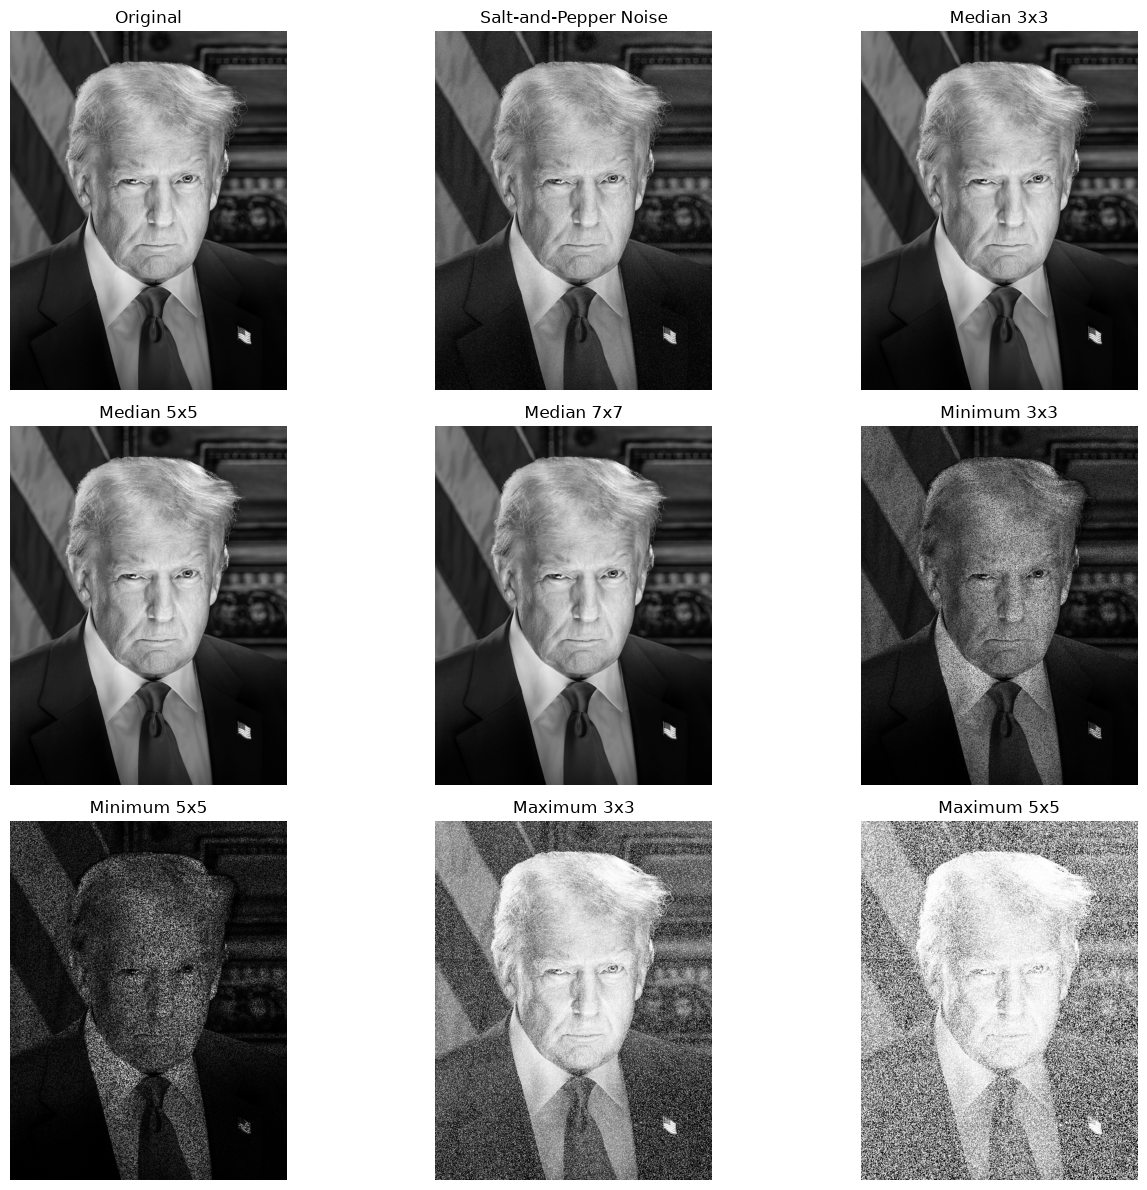

In [5]:
images = [
    image, noisy_image, median_3, median_5, median_7,
    minimum_3, minimum_5, maximum_3, maximum_5
]
titles = [
    "Original", "Salt-and-Pepper Noise", "Median 3x3", "Median 5x5",
    "Median 7x7", "Minimum 3x3", "Minimum 5x5",
    "Maximum 3x3", "Maximum 5x5"
]

plt.figure(figsize=(14, 12))

for i in range(len(images)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()